# GIFTERS: interrogating local Qwen3-0.6B
University of Toronto · AI Forensics

Three experiments: **generalizability** (observed-token likelihood), **robustness** (input changes), and **stability** (local weight changes). Run cells in order using the existing `Agentic_Workflow_Build` Python environment.

The original installed Gemma4 31B Ollama checkpoint supports generation but not the direct parameter access used here. This notebook now uses **Qwen3-0.6B**, downloaded once into `models/Qwen3-0.6B`, loaded in float32 through Transformers. All notebook inference is offline. The existing MAT186 MiniLM encoder is reused. No training is performed, and the downloaded checkpoint is never modified.

Implementation: configurable model adapters → observed-token scoring → reviewed prompt perturbations → shared ensemble statistics → reversible weight plane. Fast mode is illustrative, not a significance test. Qwen3 is instruction-tuned: document likelihood therefore describes this checkpoint, not an untouched base model. Thinking is disabled for response generation.

[Qwen model card](https://huggingface.co/Qwen/Qwen3-0.6B). Use the settings below to vary temperature, ensemble size, seed and weight radius. Rerun from the top after changing settings.


**Validated run:** `gifters_results/20261104-184042` — all three experiments executed, with six document scores, 80 response samples, ten reviewed input variants, and a 3×3 weight plane. Seven plots are saved. Original weights were restored and verified at every grid point.

In [1]:
import os, json, time, hashlib, importlib.metadata, urllib.request
from pathlib import Path
from contextlib import contextmanager
from dataclasses import dataclass, asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TRANSFORMERS_OFFLINE'] = '1'

@dataclass
class Settings:
    mode: str = 'fast'
    backend: str = 'transformers'  # 'transformers' enables scoring and weight access
    model: str = 'models/Qwen3-0.6B'
    encoder_path: str = '/Users/jae3goals/Jupyter Code on Root/MAT186/.models/all-MiniLM-L6-v2'  # local SentenceTransformer directory; no downloads
    temperature: float = 0.7
    ensemble_size: int = 2
    baseline_pairs: int = 3  # disjoint pairs: 6 independent baseline ensembles
    max_new_tokens: int = 256
    max_document_tokens: int = 192
    seed: int = 420
    perturbations_per_type: int = 1
    grid_size: int = 3
    weight_radius: float = 0.005
    device: str = 'cpu'  # change to 'mps' on a supported Apple Silicon kernel
    plane_max_parameters: int = 1_500_000_000
    response_instruction: str = 'Answer in at most 30 words, in one paragraph without headings. Include the requested limitation or significance.'

cfg = Settings()
# For a longer run: cfg.ensemble_size=8; cfg.baseline_pairs=20; cfg.grid_size=5
# cfg.model='/absolute/path/to/another/supported/local/checkpoint'
# cfg.encoder_path='/absolute/path/to/all-MiniLM-L6-v2'
assert cfg.temperature > 0 and cfg.ensemble_size >= 2 and cfg.baseline_pairs >= 2
assert cfg.grid_size >= 3 and cfg.grid_size % 2 == 1
OUT = Path('gifters_results') / time.strftime('%Y%m%d-%H%M%S')
OUT.mkdir(parents=True, exist_ok=True)
(OUT/'config.json').write_text(json.dumps(asdict(cfg), indent=2))
status = {}
versions = {p: importlib.metadata.version(p) for p in ['torch','transformers','numpy','pandas','matplotlib','sentence-transformers']}
(OUT/'versions.json').write_text(json.dumps(versions, indent=2))
print('Output:', OUT.resolve()); display(pd.Series(asdict(cfg)))

Output: /Users/jae3goals/Jupyter Code on Root/MSE420_1020_AI_Forensics/MSE420_AI_Forensics/demonstrations/gifters_results/20261104-184042


/Users/jae3goals/anaconda3/envs/Agentic_Workflow_Build/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


mode                                                                   fast
backend                                                        transformers
model                                                     models/Qwen3-0.6B
encoder_path              /Users/jae3goals/Jupyter Code on Root/MAT186/....
temperature                                                             0.7
ensemble_size                                                             2
baseline_pairs                                                            3
max_new_tokens                                                          256
max_document_tokens                                                     192
seed                                                                    420
perturbations_per_type                                                    1
grid_size                                                                 3
weight_radius                                                         0.005
device      

In [2]:
def ollama_api(endpoint, payload=None):
    # Fixed loopback endpoint; proxies cannot redirect local inference.
    request = urllib.request.Request('http://127.0.0.1:11434/api/' + endpoint,
        data=None if payload is None else json.dumps(payload).encode(),
        headers={'Content-Type':'application/json'})
    with urllib.request.build_opener(urllib.request.ProxyHandler({})).open(request, timeout=600) as r:
        return json.load(r)

inventory = {'hf_snapshots': []}
for p in (Path.home()/'.cache/huggingface/hub').glob('models--*/snapshots/*'):
    inventory['hf_snapshots'].append({'path':str(p), 'weights':bool(list(p.glob('*.safetensors')) or list(p.glob('pytorch_model*.bin')))})
try:
    inventory['ollama'] = ollama_api('tags')
except Exception as e:
    inventory['ollama_error'] = str(e)
(OUT/'inventory.json').write_text(json.dumps(inventory, indent=2))
display(inventory)

class OllamaBackend:
    editable = False
    def __init__(self, name):
        self.name = name
        info = ollama_api('show', {'model':name})
        if info.get('remote_host') or info.get('remote_model') or 'cloud' in name:
            raise ValueError('Only local models are permitted')
        if 'gemma' not in str(info.get('details', {})).lower():
            raise ValueError('Select an installed Gemma model')
        (OUT/'model_info.json').write_text(json.dumps(info, indent=2))
    def generate(self, prompt, seed, temperature=None):
        result = ollama_api('chat', {'model':self.name, 'stream':False, 'think':False,
            'messages':[{'role':'user','content':prompt}],
            'options':{'temperature':cfg.temperature if temperature is None else temperature,
                       'seed':int(seed),'num_predict':cfg.max_new_tokens,'num_ctx':2048, 'top_k':0, 'top_p':1.0}})
        if result.get('done_reason') == 'length':
            raise RuntimeError('Response hit token cap; increase max_new_tokens or shorten response_instruction and rerun')
        text = result['message']['content'].strip()
        if not text: raise RuntimeError('Empty response; increase token budget or inspect model thinking settings')
        return text

class TransformersBackend:
    editable = True
    def __init__(self, path):
        import torch
        from transformers import AutoTokenizer, AutoModelForCausalLM
        self.torch = torch
        torch.set_num_threads(4)
        self.tokenizer = AutoTokenizer.from_pretrained(path, local_files_only=True)
        self.model = AutoModelForCausalLM.from_pretrained(path, local_files_only=True,
            dtype=torch.float32).to(cfg.device).eval()
        if self.model.config.model_type not in {'qwen3','gemma','gemma2','gemma3_text'}:
            raise ValueError('Select a supported local causal language model')
        if getattr(self.model, 'is_quantized', False):
            raise ValueError('Use floating-point weights for the plane experiment')
        for p in self.model.parameters(): p.requires_grad_(False)
        self.model.config.to_json_file(str(OUT/'model_config.json'))
    def generate(self, prompt, seed, temperature=None):
        t = self.torch; t.manual_seed(int(seed))
        if cfg.device == 'mps': t.mps.manual_seed(int(seed))
        tok = self.tokenizer
        if tok.chat_template:
            prompt = tok.apply_chat_template([{'role':'user','content':prompt}], tokenize=False, add_generation_prompt=True, enable_thinking=False)
            x = tok(prompt, return_tensors='pt', add_special_tokens=False).to(cfg.device)
        else: x = tok(prompt, return_tensors='pt').to(cfg.device)
        with t.inference_mode():
            y = self.model.generate(**x, do_sample=True,
                temperature=cfg.temperature if temperature is None else temperature,
                top_p=1.0, top_k=0, max_new_tokens=cfg.max_new_tokens,
                pad_token_id=tok.eos_token_id)
        new_tokens = y[0,x.input_ids.shape[1]:]
        eos = self.model.generation_config.eos_token_id
        eos = [eos] if isinstance(eos,int) else (eos or [])
        if len(new_tokens) >= cfg.max_new_tokens and int(new_tokens[-1]) not in eos:
            raise RuntimeError('Generation hit token cap; shorten answer instruction or raise max_new_tokens')
        result = tok.decode(new_tokens, skip_special_tokens=True).strip()
        if not result: raise RuntimeError('Empty generated response')
        return result
    def token_losses(self, text):
        t = self.torch
        ids = self.tokenizer(text, return_tensors='pt', truncation=True,
            max_length=cfg.max_document_tokens).input_ids.to(cfg.device)
        if ids.shape[1] < 2: raise ValueError('Document needs at least two tokens')
        with t.inference_mode():
            logits = self.model(input_ids=ids, use_cache=False).logits[0,:-1].float()
            losses = t.nn.functional.cross_entropy(logits, ids[0,1:], reduction='none')
        return self.tokenizer.convert_ids_to_tokens(ids[0,1:].tolist()), losses.cpu().numpy()

backend = None; encoder = None
try:
    backend = OllamaBackend(cfg.model) if cfg.backend == 'ollama' else TransformersBackend(cfg.model)
    status['generation'] = 'READY'
except Exception as e: status['generation'] = 'BLOCKED: ' + str(e)
try:
    if not cfg.encoder_path: raise ValueError('Set encoder_path to a local sentence embedding model')
    from sentence_transformers import SentenceTransformer
    if (Path(cfg.encoder_path)/'modules.json').exists():
        encoder = SentenceTransformer(cfg.encoder_path, local_files_only=True, device='cpu').eval()
    else:
        # Existing MAT186 export has the transformer weights, but no pooling metadata.
        # Reconstruct MiniLM's attention-mask-aware mean pooling explicitly.
        from sentence_transformers import models
        transformer = models.Transformer(cfg.encoder_path, max_seq_length=256,
            model_args={'local_files_only':True}, tokenizer_args={'local_files_only':True})
        pooling = models.Pooling(transformer.get_word_embedding_dimension(), pooling_mode='mean')
        encoder = SentenceTransformer(modules=[transformer,pooling], device='cpu').eval()
    (OUT/'encoder_info.json').write_text(json.dumps({'path':cfg.encoder_path,
        'max_seq_length':encoder.max_seq_length,'pooling':'mean','normalized':True},indent=2))
    for p in encoder.parameters(): p.requires_grad_(False)
except Exception as e: status['encoder'] = 'BLOCKED: ' + str(e)
else: status['encoder'] = 'READY'
display(status)

{'hf_snapshots': [{'path': '/Users/jae3goals/.cache/huggingface/hub/models--google--gemma-4-26B-A4B-it/snapshots/4d7ae4984b7db7de8f8457170b3f1a419ee76d52',
   'weights': False}],
 'ollama': {'models': [{'name': 'gemma4:31b',
    'model': 'gemma4:31b',
    'modified_at': '2026-05-24T10:10:53.829768713-04:00',
    'size': 19868981791,
    'digest': '6316f0629137b426c9d9b853ffc4c8209589f30ee39aebede6285096c0ff47e7',
    'details': {'parent_model': '',
     'format': 'gguf',
     'family': 'gemma4',
     'families': ['gemma4'],
     'parameter_size': '31.3B',
     'quantization_level': 'Q4_K_M'},
    'capabilities': ['completion', 'tools', 'thinking']},
   {'name': 'devstral-small-2:latest',
    'model': 'devstral-small-2:latest',
    'modified_at': '2026-05-24T09:56:58.214856228-04:00',
    'size': 15177374099,
    'digest': '24277f07f62db8f9cb68e9dfc679ea1818a7fbac47a50eff0a701d3f645b63c8',
    'details': {'parent_model': '',
     'format': 'gguf',
     'family': 'mistral3',
     'famili


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 311/311 [00:00<00:00, 5412.66it/s]


/var/folders/4_/gyyynsks73b0myq8_fknp0680000gn/T/ipykernel_81687/3429472079.py:100: DeprecationWarning: Importing from 'sentence_transformers.models' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.modules' instead.
  from sentence_transformers import models
The Transformer `model_args` argument was renamed and is now deprecated, please use `model_kwargs` instead.


The Transformer `tokenizer_args` argument was renamed and is now deprecated, please use `processor_kwargs` instead.



Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 34893.25it/s]


/var/folders/4_/gyyynsks73b0myq8_fknp0680000gn/T/ipykernel_81687/3429472079.py:103: FutureWarning: The `get_word_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  pooling = models.Pooling(transformer.get_word_embedding_dimension(), pooling_mode='mean')


{'generation': 'READY', 'encoder': 'READY'}

## 1 · Generalizability: predicting observed text
These six **instructor-style synthetic passages**, written for this exercise, are not published literature or a representative corpus. Replace them with UTF-8 `.txt` documents below (with permission), recording provenance and group labels. Each document is scored as plain text, without a chat template. We cap length for speed and report only that prefix: the first token has no preceding context and is excluded. NLL is measured in natural-log units (nats); perplexity = exp(mean NLL).

Teacher forcing supplies the actual preceding tokens at every position. We never score the model's own generated continuation as though it were the document. Different vocabulary, styles, and inherent predictability can change likelihood; neither training-set membership, factual correctness nor out-of-distribution generalization follows from this comparison.


Teacher forcing:   0%|          | 0/6 [00:00<?, ?it/s]


Teacher forcing:  17%|█▋        | 1/6 [00:00<00:00,  6.34it/s]


Teacher forcing:  33%|███▎      | 2/6 [00:00<00:00,  8.08it/s]


Teacher forcing:  50%|█████     | 3/6 [00:00<00:00,  8.30it/s]


Teacher forcing:  67%|██████▋   | 4/6 [00:00<00:00,  8.89it/s]


Teacher forcing: 100%|██████████| 6/6 [00:00<00:00,  9.70it/s]


Teacher forcing: 100%|██████████| 6/6 [00:00<00:00,  9.03it/s]

,document,group,mean_nll,tokens,perplexity
0,Diffusion,Materials science,3.891857,36,49.001804
1,Grains,Materials science,3.131262,43,22.902870
2,Heat transfer,General science,2.929313,32,18.714773
3,Phase field,Specialized materials,4.800716,43,121.597509
4,Precipitates,Specialized materials,4.075765,44,58.895542
5,Water cycle,General science,2.152588,38,8.607103


,document,group,position,token,nll
0,Water cycle,General science,0,Ġevapor,20.647152
1,Water cycle,General science,1,ates,0.268761
2,Water cycle,General science,2,Ġfrom,0.614957
3,Water cycle,General science,3,Ġthe,0.864300
4,Water cycle,General science,4,Ġsurface,1.470350
5,Water cycle,General science,5,Ġof,0.545049
6,Water cycle,General science,6,Ġlakes,7.049457
7,Water cycle,General science,7,Ġand,0.705493
8,Water cycle,General science,8,Ġoceans,1.522448
9,Water cycle,General science,9,.,1.331234


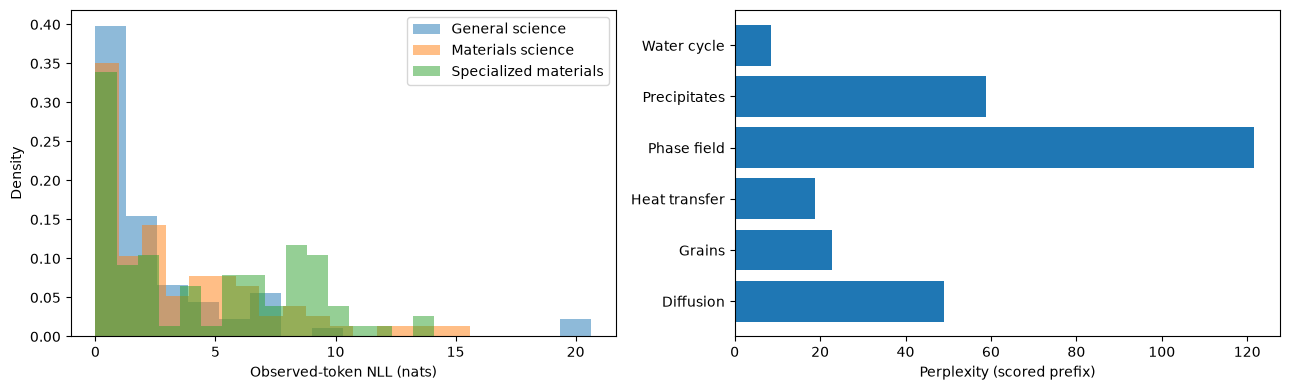

In [3]:
documents = [
 ('Water cycle','General science','Water evaporates from the surface of lakes and oceans. As moist air rises and cools, water vapor condenses into droplets. These droplets form clouds and may eventually fall as rain.'),
 ('Heat transfer','General science','Heat flows from warmer regions toward cooler regions. Conduction transfers energy through a material. Convection involves motion of a fluid, while radiation carries energy through electromagnetic waves.'),
 ('Grains','Materials science','A polycrystalline metal consists of grains with different crystallographic orientations. Grain boundaries impede dislocation motion. Reducing the average grain size often increases the yield strength, although the relationship has limits.'),
 ('Diffusion','Materials science','Atomic diffusion in a crystalline solid can proceed through vacancies. The diffusion coefficient commonly follows an Arrhenius dependence on temperature. Composition gradients drive net transport under an appropriate chemical potential gradient.'),
 ('Precipitates','Specialized materials','Coherent precipitates generate elastic misfit fields within the matrix. The competition between precipitate shearing and Orowan bypass depends on particle size, spacing, interfacial structure, and the resistance to dislocation motion.'),
 ('Phase field','Specialized materials','A Cahn–Hilliard formulation evolves a conserved composition field under gradients in variational chemical potential. Anisotropic gradient-energy coefficients and elastic coherency contributions modify interfacial morphology during spinodal decomposition.')]
# documents.append(('My paper','Specialized materials',Path('my_paper.txt').read_text()))
(OUT/'documents.json').write_text(json.dumps(documents, indent=2))
token_rows=[]
if backend is not None and backend.editable:
    for name, group, text in tqdm(documents, desc='Teacher forcing'):
        tokens, losses = backend.token_losses(text)
        token_rows.extend({'document':name,'group':group,'position':i,'token':token,'nll':float(loss)}
                          for i,(token,loss) in enumerate(zip(tokens,losses)))
    token_df=pd.DataFrame(token_rows)
    summary=token_df.groupby(['document','group']).agg(mean_nll=('nll','mean'),tokens=('nll','size')).reset_index()
    summary['perplexity']=np.exp(summary.mean_nll)
    display(summary); display(token_df.head(20))
    fig,axs=plt.subplots(1,2,figsize=(13,4))
    for group,frame in token_df.groupby('group'):
        axs[0].hist(frame.nll, bins=16, alpha=.5, density=True,label=group)
    axs[0].set(xlabel='Observed-token NLL (nats)',ylabel='Density'); axs[0].legend()
    axs[1].barh(summary.document,summary.perplexity); axs[1].set(xlabel='Perplexity (scored prefix)')
    fig.tight_layout(); fig.savefig(OUT/'generalizability.png'); plt.show()
    token_df.to_csv(OUT/'token_losses.csv',index=False); summary.to_csv(OUT/'document_scores.csv',index=False)
    status['generalizability']='EXECUTED'
else:
    status['generalizability']='BLOCKED: teacher-forced logits require local Transformers weights'
    print(status['generalizability'])

## Shared semantic measurement
Encode complete responses with one separate frozen sentence model. The code rejects responses beyond its token limit instead of silently truncating. We normalize response vectors, average them, then measure cosine distance between centroids. Within-ensemble spread is the mean distance of responses from their centroid.

Each reference distance uses **two disjoint, independently seeded baseline ensembles**. The displayed 95th percentile is descriptive, especially with three pairs; it is not a calibrated hypothesis test. A separate anchor ensemble is used for treatment comparisons. Reference pairs, anchor and treatments use fresh seeds. Rerunning the experiment cells recomputes baselines, so changes in temperature or ensemble size cannot reuse stale references. Hardware and backend differences can prevent bitwise reproducibility.

The existing MAT186 MiniLM export contains transformer weights and tokenizer files but omits the SentenceTransformer pooling configuration. We explicitly reconstruct masked mean pooling and normalization following the [model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2). The encoder is frozen and capped at 256 word pieces; longer inputs are rejected, not silently truncated. Every response ensemble receives the same fixed 30-word answer instruction. Responses that hit the generation cap are rejected.

In [4]:
def cosine_distance(a,b):
    a=np.asarray(a); b=np.asarray(b)
    denom=np.linalg.norm(a)*np.linalg.norm(b)
    if denom < 1e-12: raise ValueError('Undefined cosine distance for a zero centroid')
    return float(np.clip(1-np.dot(a,b)/denom,0,2))

def encode(texts):
    lengths=[len(encoder.tokenizer(t, truncation=False)['input_ids']) for t in texts]
    if max(lengths)>encoder.max_seq_length:
        raise ValueError('A complete response exceeds encoder context; reduce max_new_tokens and rerun')
    return np.asarray(encoder.encode(texts, normalize_embeddings=True, show_progress_bar=False))

records=[]; embeddings=[]
def ensemble(prompt, label, rng):
    texts=[]
    prompt = prompt + '\n\n' + cfg.response_instruction
    for _ in range(cfg.ensemble_size):
        seed=int(rng.integers(0,2**31-1)); response=backend.generate(prompt,seed)
        texts.append(response)
        records.append({'label':label,'prompt':prompt,'seed':seed,'temperature':cfg.temperature,'response':response})
        # Save progressively so interrupted runs retain actual generated text.
        (OUT/'responses.json').write_text(json.dumps(records,indent=2))
    E=encode(texts); embeddings.append((label,E))
    center=E.mean(axis=0)
    spread=np.mean([cosine_distance(e,center) for e in E])
    return center,float(spread),E

def baseline(prompt, label, rng):
    distances=[]
    for i in tqdm(range(cfg.baseline_pairs),desc=label+' reference pairs'):
        a,_,_=ensemble(prompt,f'{label}/reference/{i}/a',rng)
        b,_,_=ensemble(prompt,f'{label}/reference/{i}/b',rng)
        distances.append(cosine_distance(a,b))
    anchor,spread,E=ensemble(prompt,label+'/anchor',rng)
    return np.asarray(distances),anchor,spread,E

def comparison_plot(reference, frame, filename):
    fig,axs=plt.subplots(1,2,figsize=(12,4))
    axs[0].hist(reference,bins=max(3,len(reference)//2),label='Independent baseline pairs')
    axs[0].set(xlabel='Centroid cosine distance',ylabel='Count'); axs[0].legend()
    axs[1].barh(frame.label,frame.distance)
    axs[1].axvline(np.quantile(reference,.95),color='r',ls='--',label='Baseline 95th percentile (descriptive)')
    axs[1].set(xlabel='Distance from separate original anchor'); axs[1].legend()
    fig.tight_layout(); fig.savefig(OUT/filename); plt.show()

semantic_ready = backend is not None and encoder is not None
print('Semantic experiments ready:',semantic_ready)

Semantic experiments ready: True


## 2 · Robustness: change the prompt, inspect meaning
Qwen proposes the edits itself. Review the table before running the response experiment: remove any row whose meaning changes, or edit the text. `reviewed=False` is deliberate; change it to `True` after inspection. Automatic generation does not guarantee meaning preservation. Character edit ratio is only a surface-change magnitude, not a semantic measurement. Short prompts make sentence reordering less informative.

For the default prompts, failed unchanged outputs receive explicit reviewed corrections in the next cell. Both the raw generated edit and the actual tested edit are retained, with provenance. These corrected rows measure the effects of reviewed input changes; they are not evidence that Qwen successfully generated those changes.

In [5]:
prompts = [
 'Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.',
 'Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.']
edit_types = {
 'paraphrase':'Rephrase using different words.',
 'misspellings':'Introduce two modest spelling mistakes.',
 'punctuation':'Change punctuation only.',
 'formatting':'Change whitespace or line breaks only.',
 'sentence reorder':'Reorder the sentences without changing their words.'}
perturbation_rows=[]
if backend is not None:
    for pi,prompt in enumerate(tqdm(prompts,desc='Prompt perturbations')):
        for ti,(kind,instruction) in enumerate(edit_types.items()):
            for rep in range(cfg.perturbations_per_type):
                edited=backend.generate('Edit the text below. '+instruction+
                    ' Preserve its meaning. Return only the edited text, no explanation. TEXT:\n'+prompt,
                    cfg.seed+10000+pi*1000+ti*100+rep,temperature=.3)
                perturbation_rows.append({'prompt_id':pi,'type':kind,'original':prompt,'edited':edited,'reviewed':False})
    perturbations=pd.DataFrame(perturbation_rows)
    perturbations.to_csv(OUT/'perturbations.csv',index=False)
    with pd.option_context('display.max_colwidth',None): display(perturbations)
else:
    perturbations=pd.DataFrame(columns=['prompt_id','type','original','edited','reviewed'])
    print('BLOCKED: no generation backend')


Prompt perturbations:   0%|          | 0/2 [00:00<?, ?it/s]


Prompt perturbations:  50%|█████     | 1/2 [00:03<00:03,  3.52s/it]


Prompt perturbations: 100%|██████████| 2/2 [00:07<00:00,  3.61s/it]


Prompt perturbations: 100%|██████████| 2/2 [00:07<00:00,  3.60s/it]

,prompt_id,type,original,edited,reviewed
0,0,paraphrase,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Explain why reducing the size of metal grains can enhance strength. Discuss one limitation of this explanation.,False
1,0,misspellings,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,False
2,0,punctuation,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,False
3,0,formatting,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,False
4,0,sentence reorder,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,False
5,1,paraphrase,Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.,Describe how temperature influences atomic diffusion in a solid. Explain why this is important during heat treatment.,False
6,1,misspellings,Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.,Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.,False
7,1,punctuation,Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.,Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.,False
8,1,formatting,Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.,Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.,False
9,1,sentence reorder,Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.,Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.,False


In [6]:
# The small model sometimes copies its input instead of following an edit request.
# Preserve its raw output and explicitly record reviewed corrections for these examples.
reviewed_paraphrases = {
'Explain why reducing the size of metal grains can enhance strength. Discuss one limitation of this explanation.',
'Describe how temperature influences atomic diffusion in a solid. Explain why this is important during heat treatment.'}
corrections = {
(0,'misspellings'): 'Explain why making metal grains smaller can increase strenght. Discuss one limatation of this explanation.',
(1,'misspellings'): 'Describe how temperture affects atomic diffusion in a solid. Explain why this matters during heat treatement.',
(0,'punctuation'): 'Explain why making metal grains smaller can increase strength; discuss one limitation of this explanation.',
(1,'punctuation'): 'Describe how temperature affects atomic diffusion in a solid; explain why this matters during heat treatment.',
(0,'formatting'): 'Explain why making metal grains smaller can increase strength.\nDiscuss one limitation of this explanation.',
(1,'formatting'): 'Describe how temperature affects atomic diffusion in a solid.\nExplain why this matters during heat treatment.',
(0,'sentence reorder'): 'Discuss one limitation of this explanation. Explain why making metal grains smaller can increase strength.',
(1,'sentence reorder'): 'Explain why this matters during heat treatment. Describe how temperature affects atomic diffusion in a solid.'}
perturbations['generated_edit'] = perturbations.edited
perturbations['review_note'] = 'Needs inspection'
for idx,row in perturbations.iterrows():
    if row.edited in reviewed_paraphrases:
        perturbations.loc[idx,['reviewed','review_note']] = [True,'Generated paraphrase inspected']
    elif row.edited == row.original and row.original == prompts[row.prompt_id]:
        key = (row.prompt_id,row.type)
        if key in corrections and row.original in {
            'Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.',
            'Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.'}:
            perturbations.loc[idx,['edited','reviewed','review_note']] = [corrections[key],True,
                'Model returned unchanged input; explicit reviewed correction applied']
with pd.option_context('display.max_colwidth',None): display(perturbations)
# Inspect unreviewed rows before enabling them. Corrections apply only to the two
# exact teaching prompts above; new prompts require fresh review.


,prompt_id,type,original,edited,reviewed,generated_edit,review_note
0,0,paraphrase,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Explain why reducing the size of metal grains can enhance strength. Discuss one limitation of this explanation.,True,Explain why reducing the size of metal grains can enhance strength. Discuss one limitation of this explanation.,Generated paraphrase inspected
1,0,misspellings,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Explain why making metal grains smaller can increase strenght. Discuss one limatation of this explanation.,True,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Model returned unchanged input; explicit reviewed correction applied
2,0,punctuation,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Explain why making metal grains smaller can increase strength; discuss one limitation of this explanation.,True,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Model returned unchanged input; explicit reviewed correction applied
3,0,formatting,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Explain why making metal grains smaller can increase strength.\nDiscuss one limitation of this explanation.,True,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Model returned unchanged input; explicit reviewed correction applied
4,0,sentence reorder,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Discuss one limitation of this explanation. Explain why making metal grains smaller can increase strength.,True,Explain why making metal grains smaller can increase strength. Discuss one limitation of this explanation.,Model returned unchanged input; explicit reviewed correction applied
5,1,paraphrase,Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.,Describe how temperature influences atomic diffusion in a solid. Explain why this is important during heat treatment.,True,Describe how temperature influences atomic diffusion in a solid. Explain why this is important during heat treatment.,Generated paraphrase inspected
6,1,misspellings,Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.,Describe how temperture affects atomic diffusion in a solid. Explain why this matters during heat treatement.,True,Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.,Model returned unchanged input; explicit reviewed correction applied
7,1,punctuation,Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.,Describe how temperature affects atomic diffusion in a solid; explain why this matters during heat treatment.,True,Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.,Model returned unchanged input; explicit reviewed correction applied
8,1,formatting,Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.,Describe how temperature affects atomic diffusion in a solid.\nExplain why this matters during heat treatment.,True,Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.,Model returned unchanged input; explicit reviewed correction applied
9,1,sentence reorder,Describe how temperature affects atomic diffusion in a solid. Explain why this matters during heat treatment.,Explain why this matters during heat treatment. Describe how temperature affects atomic diffusion in a solid.,T


robustness/0 reference pairs:   0%|          | 0/3 [00:00<?, ?it/s]


robustness/0 reference pairs:  33%|███▎      | 1/3 [00:07<00:14,  7.15s/it]


robustness/0 reference pairs:  67%|██████▋   | 2/3 [00:13<00:06,  6.87s/it]


robustness/0 reference pairs: 100%|██████████| 3/3 [00:20<00:00,  6.72s/it]


robustness/0 reference pairs: 100%|██████████| 3/3 [00:20<00:00,  6.79s/it]


Perturbed ensembles:   0%|          | 0/5 [00:00<?, ?it/s]

... (2 outputs left out)


Perturbed ensembles:  60%|██████    | 3/5 [00:11<00:08,  4.08s/it]


Perturbed ensembles:  80%|████████  | 4/5 [00:15<00:03,  3.85s/it]


Perturbed ensembles: 100%|██████████| 5/5 [00:18<00:00,  3.76s/it]


Perturbed ensembles: 100%|██████████| 5/5 [00:18<00:00,  3.78s/it]

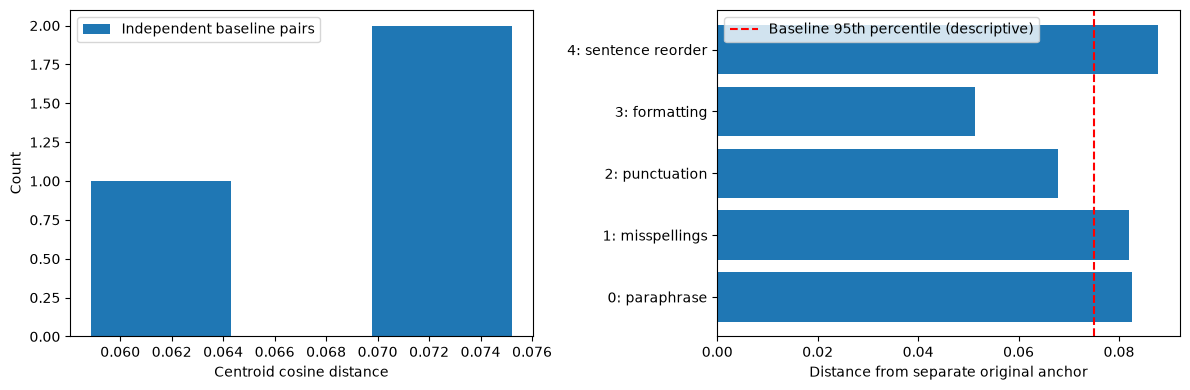

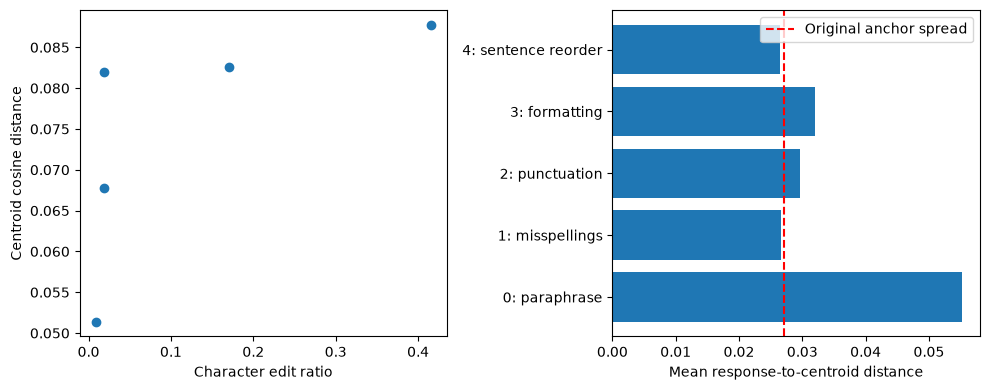


robustness/1 reference pairs:   0%|          | 0/3 [00:00<?, ?it/s]


robustness/1 reference pairs:  33%|███▎      | 1/3 [00:08<00:16,  8.04s/it]


robustness/1 reference pairs:  67%|██████▋   | 2/3 [00:16<00:08,  8.37s/it]


robustness/1 reference pairs: 100%|██████████| 3/3 [00:25<00:00,  8.58s/it]


robustness/1 reference pairs: 100%|██████████| 3/3 [00:25<00:00,  8.49s/it]


Perturbed ensembles:   0%|          | 0/5 [00:00<?, ?it/s]

... (2 outputs left out)


Perturbed ensembles:  60%|██████    | 3/5 [00:11<00:07,  3.92s/it]


Perturbed ensembles:  80%|████████  | 4/5 [00:16<00:04,  4.43s/it]


Perturbed ensembles: 100%|██████████| 5/5 [00:21<00:00,  4.61s/it]


Perturbed ensembles: 100%|██████████| 5/5 [00:21<00:00,  4.35s/it]

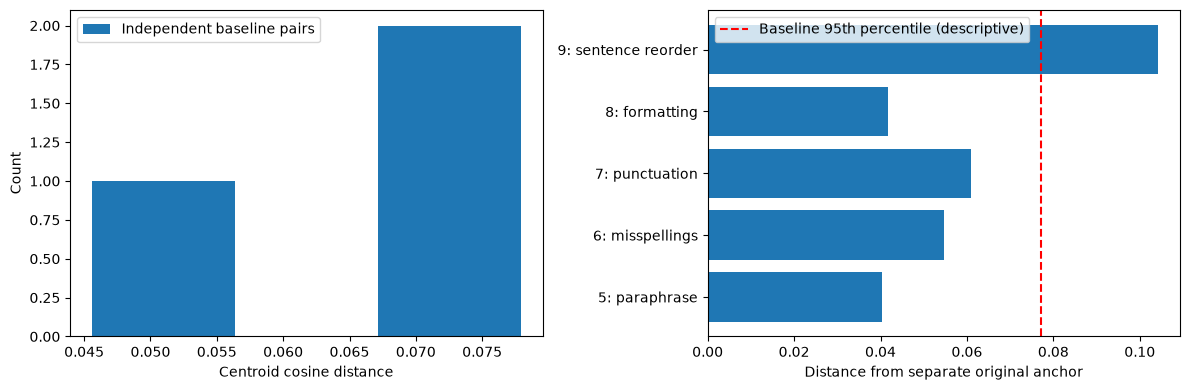

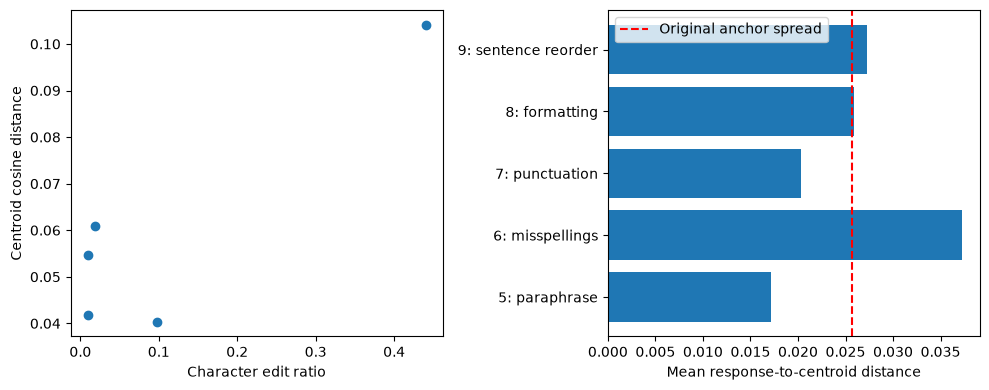

In [7]:
import difflib
robustness=[]
if semantic_ready and len(perturbations) and perturbations.reviewed.any():
    rng=np.random.default_rng(cfg.seed)
    for pi,prompt in enumerate(prompts):
        selected=perturbations[(perturbations.prompt_id==pi)&perturbations.reviewed]
        if selected.empty: continue
        ref,anchor,base_spread,base_E=baseline(prompt,f'robustness/{pi}',rng)
        rows=[]
        for idx,row in tqdm(selected.iterrows(),total=len(selected),desc='Perturbed ensembles'):
            center,spread,E=ensemble(row.edited,f'robustness/{pi}/edit/{idx}',rng)
            rows.append({'label':str(idx)+': '+row.type,'prompt_id':pi,'distance':cosine_distance(center,anchor),
                         'within_spread':spread,'baseline_spread':base_spread,
                         'edit_ratio':1-difflib.SequenceMatcher(None,prompt,row.edited).ratio()})
        frame=pd.DataFrame(rows); robustness.extend(rows)
        comparison_plot(ref,frame,f'robustness_{pi}.png')
        np.save(OUT/f'robustness_reference_{pi}.npy',ref)
        fig,axs=plt.subplots(1,2,figsize=(10,4))
        axs[0].scatter(frame.edit_ratio,frame.distance)
        axs[0].set(xlabel='Character edit ratio',ylabel='Centroid cosine distance')
        axs[1].barh(frame.label,frame.within_spread)
        axs[1].axvline(base_spread,ls='--',color='r',label='Original anchor spread')
        axs[1].set(xlabel='Mean response-to-centroid distance'); axs[1].legend()
        fig.tight_layout(); fig.savefig(OUT/f'robustness_spread_{pi}.png'); plt.show()
    pd.DataFrame(robustness).to_csv(OUT/'robustness.csv',index=False)
    perturbations.to_csv(OUT/'reviewed_perturbations.csv',index=False)
    status['robustness']='EXECUTED for reviewed rows only'
else:
    status['robustness']='BLOCKED: needs generator, separate encoder, and reviewed perturbations'
    print(status['robustness'])

## 3 · Stability: a reversible random weight plane
For each unique floating-point parameter tensor W, draw independent Gaussian directions D₁, D₂ and scale each to ||W||₂. The plane is W + αD₁ + βD₂. Directions are reproducible, tensor-normalized, and not assumed exactly orthogonal. Zero-norm tensors remain unchanged; tied parameters are visited once. The coordinates are relative per-tensor perturbation scales, not percentages of semantic change.

The implementation keeps an exact CPU copy of the original parameters and recreates directions deterministically one tensor at a time. Every grid point starts from that copy; a `finally` block restores and checks exact equality even if generation fails. There is no cumulative add/subtract drift. Memory still includes the original model, one full CPU copy, and temporary tensors. A parameter-count guard blocks large models. Hard process termination cannot run Python cleanup; reload the original checkpoint after a kernel crash. Nothing writes modified weights to the installed checkpoint.

Use a small floating-point causal language model. This measures local parameter sensitivity, **not reproducibility of training**. The center cell uses a fresh ensemble and need not have zero distance from the separately sampled original anchor.


stability reference pairs:   0%|          | 0/3 [00:00<?, ?it/s]


stability reference pairs:  33%|███▎      | 1/3 [00:06<00:12,  6.29s/it]


stability reference pairs:  67%|██████▋   | 2/3 [00:13<00:06,  6.85s/it]


stability reference pairs: 100%|██████████| 3/3 [00:20<00:00,  6.81s/it]


stability reference pairs: 100%|██████████| 3/3 [00:20<00:00,  6.76s/it]


Weight plane rows:   0%|          | 0/3 [00:00<?, ?it/s]


Weight plane rows:  33%|███▎      | 1/3 [00:35<01:10, 35.12s/it]


Weight plane rows:  67%|██████▋   | 2/3 [00:55<00:26, 26.53s/it]


Weight plane rows: 100%|██████████| 3/3 [01:32<00:00, 31.22s/it]


Weight plane rows: 100%|██████████| 3/3 [01:32<00:00, 30.81s/it]

,label,alpha,beta,distance,within_spread
0,"(-0.005, -0.005)",-0.005,-0.005,0.043654,0.030467
1,"(0, -0.005)",0.000,-0.005,0.048448,0.031713
2,"(0.005, -0.005)",0.005,-0.005,0.022413,0.019677
3,"(-0.005, 0)",-0.005,0.000,0.070470,0.040849
4,"(0, 0)",0.000,0.000,0.102878,0.057365
5,"(0.005, 0)",0.005,0.000,0.060975,0.048715
6,"(-0.005, 0.005)",-0.005,0.005,0.043017,0.033289
7,"(0, 0.005)",0.000,0.005,0.035422,0.030318
8,"(0.005, 0.005)",0.005,0.005,0.057932,0.021133


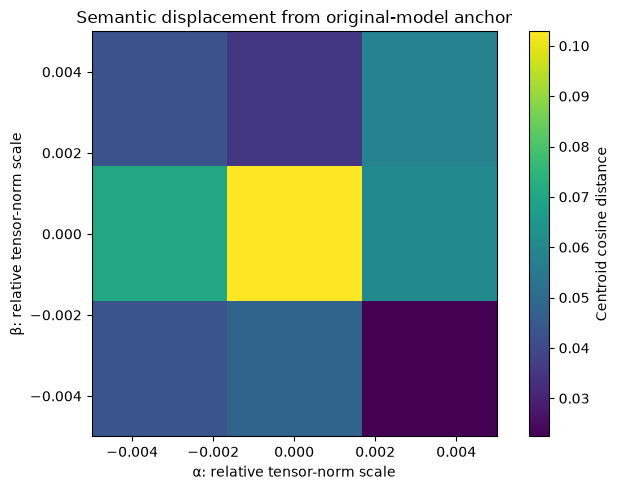

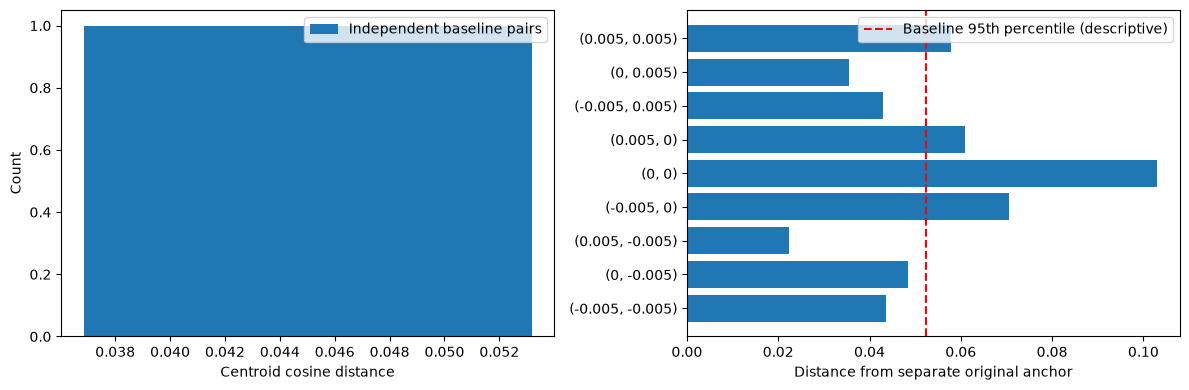

In [8]:
class WeightPlane:
    def __init__(self, model, seed, max_parameters):
        import torch
        self.torch=torch; self.model=model; self.seed=seed
        self.params=list(model.named_parameters())
        if sum(p.numel() for _,p in self.params)>max_parameters:
            raise ValueError('Model exceeds plane memory guard; use a smaller local checkpoint')
        if any(not p.is_floating_point() for _,p in self.params):
            raise ValueError('Random plane requires floating-point parameters')
        self.original={name:p.detach().cpu().clone() for name,p in self.params}
    def direction(self, base, index, axis):
        t=self.torch; g=t.Generator(device='cpu').manual_seed(self.seed+2*index+axis)
        d=t.randn(base.shape,generator=g,dtype=t.float32)
        norm=d.norm()
        if norm>0: d.mul_(base.float().norm()/norm)
        return d
    def restore(self):
        with self.torch.no_grad():
            for name,p in self.params: p.copy_(self.original[name].to(p.device))
        for name,p in self.params:
            if not self.torch.equal(p.detach().cpu(),self.original[name]):
                raise RuntimeError('Weight restoration failed: '+name)
    @contextmanager
    def at(self, alpha, beta):
        try:
            with self.torch.no_grad():
                for i,(name,p) in enumerate(self.params):
                    base=self.original[name]
                    changed=base.float().clone()
                    if alpha: changed.add_(self.direction(base,i,0),alpha=float(alpha))
                    if beta: changed.add_(self.direction(base,i,1),alpha=float(beta))
                    p.copy_(changed.to(device=p.device,dtype=p.dtype))
            yield
        finally: self.restore()

stability_prompt=prompts[0]
if semantic_ready and backend.editable:
    rng=np.random.default_rng(cfg.seed+200000)
    ref,anchor,spread,E=baseline(stability_prompt,'stability',rng)
    plane=WeightPlane(backend.model,cfg.seed,cfg.plane_max_parameters)
    axis=np.linspace(-cfg.weight_radius,cfg.weight_radius,cfg.grid_size)
    rows=[]; grid=np.zeros((len(axis),len(axis)))
    for j,beta in enumerate(tqdm(axis,desc='Weight plane rows')):
        for i,alpha in enumerate(axis):
            with plane.at(alpha,beta):
                center,within,_=ensemble(stability_prompt,f'plane/{j}/{i}',rng)
            grid[j,i]=cosine_distance(center,anchor)
            rows.append({'label':f'({alpha:.4g}, {beta:.4g})','alpha':alpha,'beta':beta,
                         'distance':grid[j,i],'within_spread':within})
    frame=pd.DataFrame(rows); display(frame)
    frame.to_csv(OUT/'stability.csv',index=False); np.save(OUT/'stability_reference.npy',ref)
    fig,ax=plt.subplots(figsize=(7,5))
    im=ax.imshow(grid,origin='lower',extent=[axis[0],axis[-1],axis[0],axis[-1]],aspect='equal')
    ax.set(xlabel='α: relative tensor-norm scale',ylabel='β: relative tensor-norm scale',
           title='Semantic displacement from original-model anchor')
    fig.colorbar(im,ax=ax,label='Centroid cosine distance')
    fig.tight_layout(); fig.savefig(OUT/'weight_plane.png'); plt.show()
    comparison_plot(ref,frame,'stability_baseline.png')
    status['stability']='EXECUTED; original weights restored and verified at each point'
    del plane
else:
    status['stability']='BLOCKED: requires editable local floating-point weights and separate encoder'
    print(status['stability'])

## Interpretation and reproducibility
- Semantic similarity approximates meaning; a similar embedding can conceal a wrong number, negation or factual error. Inspect the saved complete responses.
- A frozen semantic encoder has its own training biases and domain limitations. Freezing makes a consistent instrument, not an unbiased one.
- Temperature controls decoding variability; it does not directly measure intrinsic model uncertainty. Compare experiments within a backend, with all decoding settings held constant.
- The baseline is conditional on the prompt, model, encoder, temperature, response length and ensemble size. Small fast-mode ensembles give noisy centroids and a very coarse reference distribution.
- Text predictability does not establish truth or training-distribution membership. These synthetic document groups cannot support population-wide claims.
- Random planes sample just two directions in a vast parameter space. This is local sensitivity, not training stability.
- These measurements probe aspects of trustworthiness, not whether a model reasons or understands.

Discussion: Which edits preserve meaning? Does a larger ensemble reduce baseline displacement? Is a low-displacement answer still scientifically wrong? How do conclusions change with a different encoder?

Optional PCA visualizations should always be labeled as projections that can distort distances; all distances here use the full embeddings.

Technical references: [Transformers local model loading](https://huggingface.co/docs/transformers/main_classes/model), [Ollama API specification](https://github.com/ollama/ollama/blob/main/docs/openapi.yaml), [Sentence Transformers model API](https://sbert.net/docs/package_reference/sentence_transformer/SentenceTransformer.html). Ollama generated-token logprobs are not a substitute for observed-document teacher forcing.

In [9]:
if embeddings:
    np.savez_compressed(OUT/'response_embeddings.npz',**{f'ensemble_{i}':E for i,(_,E) in enumerate(embeddings)})
    (OUT/'embedding_labels.json').write_text(json.dumps([label for label,_ in embeddings],indent=2))
(OUT/'status.json').write_text(json.dumps(status,indent=2))
display(pd.Series(status,name='Execution status'))
if any(str(v).startswith('BLOCKED') for v in status.values()):
    print('Read BLOCKED literally: those experiments have not produced measurements.')
print('Saved configuration, versions, inventory, texts and available measurements to',OUT.resolve())

generation                                                      READY
encoder                                                         READY
generalizability                                             EXECUTED
robustness                            EXECUTED for reviewed rows only
stability           EXECUTED; original weights restored and verifi...
Name: Execution status, dtype: str

Saved configuration, versions, inventory, texts and available measurements to /Users/jae3goals/Jupyter Code on Root/MSE420_1020_AI_Forensics/MSE420_AI_Forensics/demonstrations/gifters_results/20261104-184042
